# 06. Sori Estimation via Reduced Sampling

Counting the exact number of sori in every row of a frond is labor-intensive, especially when
scaling the analysis to more individuals. `03_spatial_distribution_imputation` already defined 5
reference points along the fertile zone (base, Q1, center, Q3, apex) to study distribution shape,
and although no correlation robust enough to support a parametric model was found between these
points and morphometric variables, the information in their position and magnitude is still
useful for a different purpose: approximating an individual's total sori count using only a
handful of these points, instead of every row.

This works because these points are not isolated measurements, they are samples of a continuous
sori-density curve along the frond. Under this framing, estimating total sori count becomes a
numerical integration problem: approximating the area under the sori-density curve (i.e., the
total count) from a reduced number of sampled points. This notebook tests two classic numerical
integration methods, Simpson's rule and the trapezoidal rule, along with their average,
validating each against the real row-by-row counts of the 23 individuals with complete data. It
also tests whether a finer 9-point resolution meaningfully improves on the original 5-point
scheme, to evaluate whether counting only a small number of strategic rows, instead of the
typical 60-100, allows a reasonably accurate and biologically grounded estimate for future
individuals.

## 1. Import Libraries

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.stats import wilcoxon
plt.rcdefaults()


## 2. Load Data

We load the row-level dataset from `03_spatial_distribution_imputation`, which includes all 24 individuals (23 real, 1 imputed for H15). We separate out the 23 real individuals, since only they have a true total sori count to validate the estimation methods against.

In [32]:
df_sori_imputed = pd.read_csv("../data/processed/sori_imputed.csv")
df_sori_real = df_sori_imputed[df_sori_imputed["is_imputed"] == False].reset_index(drop=True)

print(f"df_sori_imputed: {df_sori_imputed.shape[0]} rows ({df_sori_imputed['individual_id'].nunique()} individuals)")
print(f"df_sori_real: {df_sori_real.shape[0]} rows ({df_sori_real['individual_id'].nunique()} individuals)")

df_sori_imputed: 1921 rows (24 individuals)
df_sori_real: 1835 rows (23 individuals)


## 3. Recomputing the 5 Characteristic Points

`03_spatial_distribution_imputation` (Section 6.4.1) later quantified how reconstruction
fidelity scales with the number of sampled points, showing n=5 as an adequate, though not
saturating, resolution, most of the achievable fidelity is already captured, with diminishing
returns beyond it. That result measures shape reconstruction fidelity, though, not the
total-count estimation error this notebook cares about. Section 9 tests this directly, in this
notebook's own metric, checking whether adding more points meaningfully improves the total sori
estimate.

In [33]:
df_sori_real = df_sori_real.copy()
df_sori_real["n_rows_total"] = df_sori_real.groupby("individual_id")["row_id"].transform("max")
df_sori_real["relative_position"] = df_sori_real["row_id"] / df_sori_real["n_rows_total"]


def extract_five_points(group):
    group = group.sort_values("row_id", ascending=True).reset_index(drop=True)
    with_sori = group[group["n_sori_per_row"] > 0]

    idx_start = with_sori.index.min()
    idx_end = with_sori.index.max()
    fertile_zone = group.loc[idx_start:idx_end].reset_index(drop=True)
    n_fertile_rows = len(fertile_zone)

    five_indices = np.linspace(0, n_fertile_rows - 1, 5).round().astype(int)
    positions = fertile_zone.loc[five_indices, "relative_position"].values
    values = fertile_zone.loc[five_indices, "n_sori_per_row"].values

    return pd.Series({
        "base_pos": positions[0], "sori_base": values[0],
        "q1_pos": positions[1], "sori_q1": values[1],
        "center_pos": positions[2], "sori_center": values[2],
        "q3_pos": positions[3], "sori_q3": values[3],
        "apex_pos": positions[4], "sori_apex": values[4],
        "n_fertile_rows": n_fertile_rows,
        "n_rows_total": group["n_rows_total"].iloc[0],
        "total_real": group["n_sori_per_row"].sum(),
    })


df_shape_points = (
    df_sori_real.groupby("individual_id")
    .apply(extract_five_points, include_groups=False)
    .reset_index()
)

df_shape_points.round(3)

,individual_id,base_pos,sori_base,q1_pos,sori_q1,center_pos,sori_center,q3_pos,sori_q3,apex_pos,sori_apex,n_fertile_rows,n_rows_total,total_real
0,H01,0.128,12.0,0.256,52.0,0.384,54.0,0.512,22.0,0.640,4.0,45.0,86.0,1656.0
1,H02,0.237,36.0,0.424,50.0,0.610,36.0,0.780,26.0,0.966,4.0,44.0,59.0,1554.0
2,H03,0.262,28.0,0.412,48.0,0.562,52.0,0.700,12.0,0.850,4.0,48.0,80.0,1728.0
3,H04,0.202,16.0,0.348,52.0,0.494,40.0,0.652,14.0,0.798,6.0,54.0,89.0,1826.0
4,H05,0.256,30.0,0.402,40.0,0.537,48.0,0.671,22.0,0.817,6.0,47.0,82.0,1456.0
5,H06,0.294,18.0,0.424,30.0,0.553,42.0,0.694,28.0,0.824,2.0,46.0,85.0,1290.0
6,H07,0.242,32.0,0.374,46.0,0.505,38.0,0.648,16.0,0.780,2.0,50.0,91.0,1590.0
7,H08,0.395,2.0,0.494,34.0,0.593,24.0,0.679,18.0,0.778,4.0,32.0,81.0,644.0
8,H09,0.405,10.0,0.554,52.0,0.703,42.0,0.838,12.0,0.986,4.0,44.0,74.0,1296.0
9,H10,0.161,18.0,0.355,46.0,0.548,32.0,0.726,26.0,0.919,4.0,48.0,62.0,1464.0


Note that `extract_five_points` here is deliberately different from its namesake in
`03_spatial_distribution_imputation` (Section 5): that version interpolates sori values at exact
fractional positions to build continuous, comparable curves for the correlation analysis, while
this version snaps each position to the nearest real row index instead, since the whole premise
of this notebook is counting rows that actually exist in the field, not interpolated values.

3.1 Equidistance check 

We verify that the 5 sampled points are evenly spaced along the fertile zone, as intended by
`np.linspace`, by checking the gap between consecutive point positions across all 23 individuals.

In [34]:
position_cols = ["base_pos", "q1_pos", "center_pos", "q3_pos", "apex_pos"]
gaps = df_shape_points[position_cols].diff(axis=1).iloc[:, 1:]
gaps.columns = ["base_to_q1", "q1_to_center", "center_to_q3", "q3_to_apex"]

gaps_check = pd.DataFrame({
    "individual_id": df_shape_points["individual_id"],
    "gap_min": gaps.min(axis=1),
    "gap_max": gaps.max(axis=1),
    "gap_mean": gaps.mean(axis=1),
})
gaps_check["relative_spread_pct"] = (
    (gaps_check["gap_max"] - gaps_check["gap_min"]) / gaps_check["gap_mean"] * 100
).round(1)

print(f"Mean relative spread within individuals: {gaps_check['relative_spread_pct'].mean():.1f}%")
print(f"Max relative spread within individuals:  {gaps_check['relative_spread_pct'].max():.1f}%")

gaps_check.sort_values("relative_spread_pct", ascending=False).round(4)

Mean relative spread within individuals: 7.2%
Max relative spread within individuals:  13.8%


,individual_id,gap_min,gap_max,gap_mean,relative_spread_pct
14,H16,0.1667,0.1905,0.1726,13.8
7,H08,0.0864,0.0988,0.0957,12.9
17,H19,0.0909,0.1023,0.0938,12.1
15,H17,0.1286,0.1429,0.1357,10.5
21,H23,0.1299,0.1429,0.1331,9.8
8,H09,0.1351,0.1486,0.1453,9.3
1,H02,0.1695,0.1864,0.1822,9.3
5,H06,0.1294,0.1412,0.1324,8.9
4,H05,0.1341,0.1463,0.1402,8.7
9,H10,0.1774,0.1935,0.1895,8.5


To confirm that the remaining spread comes from rounding fractional positions to integer row
indices, we test whether it correlates with the number of fertile rows: shorter fertile zones
should absorb the same rounding error as a larger fraction of the spacing, producing a negative
correlation between `n_fertile_rows` and relative spread.

In [35]:
gaps_check = gaps_check.merge(df_shape_points[["individual_id", "n_fertile_rows"]], on="individual_id")

rho, p = spearmanr(gaps_check["n_fertile_rows"], gaps_check["relative_spread_pct"])
print(f"Spearman rho = {rho:.3f}, p = {p:.3f}")

gaps_check.sort_values("n_fertile_rows")[["individual_id", "n_fertile_rows", "relative_spread_pct"]]

Spearman rho = -0.485, p = 0.019


,individual_id,n_fertile_rows,relative_spread_pct
18,H20,29.0,0.0
14,H16,30.0,13.8
7,H08,32.0,12.9
17,H19,34.0,12.1
12,H13,37.0,0.0
15,H17,39.0,10.5
21,H23,42.0,9.8
8,H09,44.0,9.3
1,H02,44.0,9.3
0,H01,45.0,0.0


The 5 points are equidistant by construction (`np.linspace` generates evenly spaced fractions
within the fertile zone), and the check confirms this holds well in practice: mean relative
spread across individuals is 7.2%, with several individuals (H01, H20, H21, H22) showing exactly
0.0% spread. The main source of the remaining spread is rounding fractional positions to integer
row indices, individuals with fewer fertile rows absorb that rounding as a larger fraction of the
spacing (Spearman rho = -0.485, p = 0.019, confirming shorter fertile zones show more spread).
H16, the individual with the largest spread (13.8%), is also the individual with the largest
Simpson and Trapezoid error, though H03 and H21 (also high-error individuals) show low or zero
spread, suggesting spacing irregularity is at most a secondary contributor to error, consistent
with Section 5.3's finding that error is driven primarily by peak shape rather than sampling
irregularity.

## 4. Visual Check: Is the Distribution Shape Suitable for Simpson's Rule?

Before applying Simpson's rule, we visualize the sori-distribution shape for all 23 individuals with real data, confirming that most show a relatively smooth unimodal pattern, a favorable condition for the parabolic approximation to capture the real curve well, in contrast to more erratic shapes or multiple peaks, where Simpson's rule would perform poorly. The 5 characteristic points (red) are overlaid on each curve to visualize how well they sample its shape.

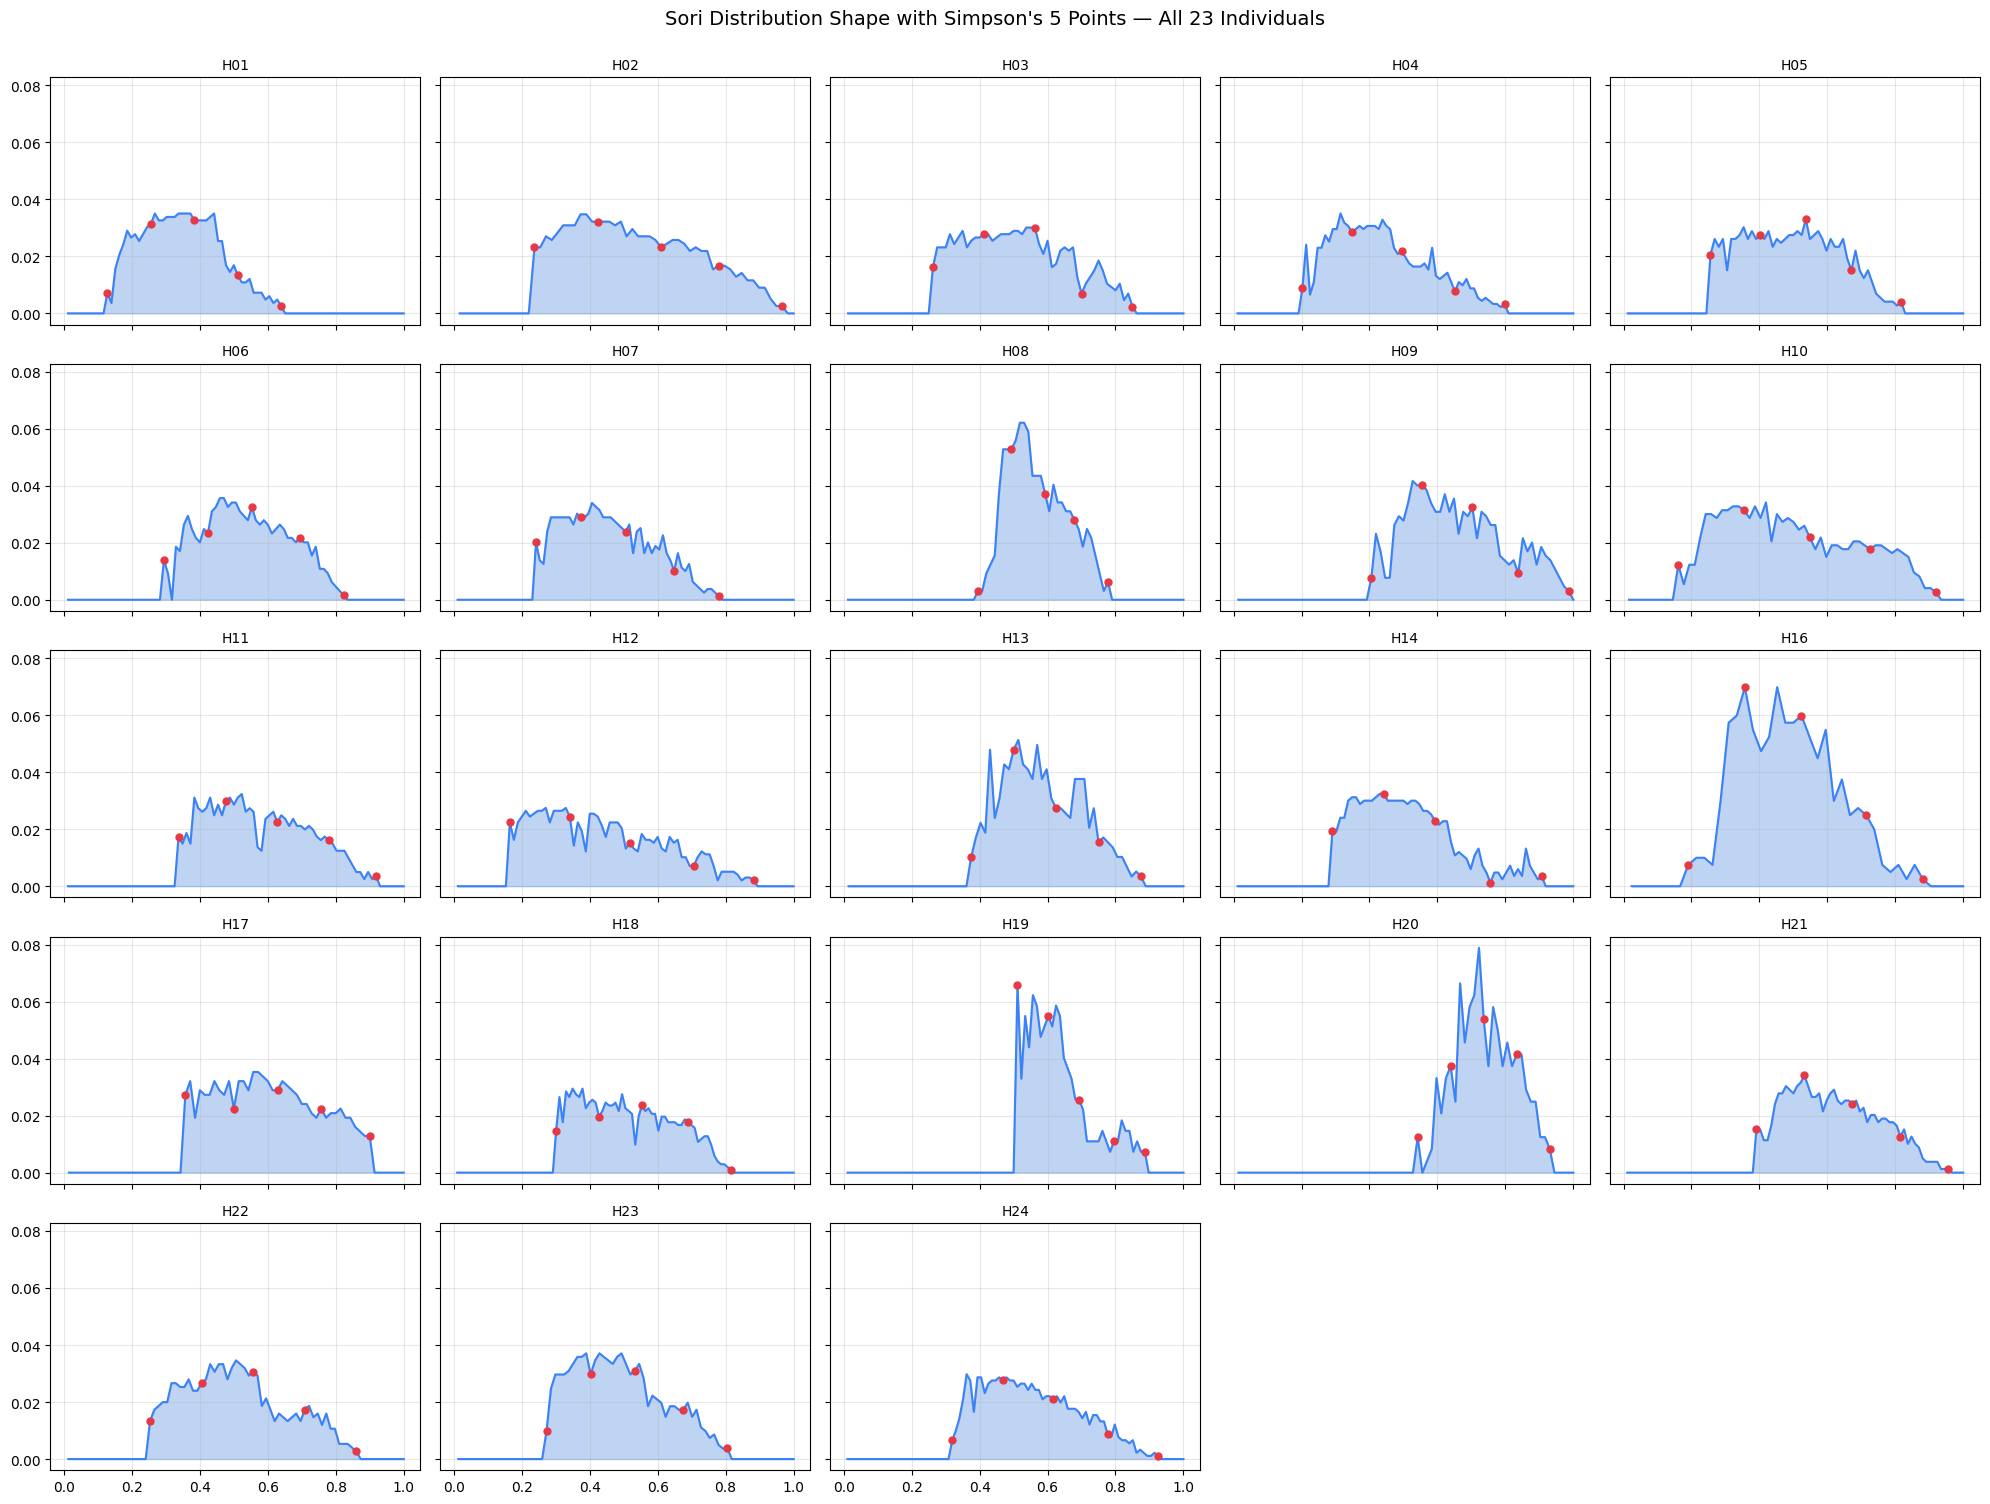

In [36]:
ids = sorted(df_sori_real["individual_id"].unique())

n_cols = 5
n_rows = int(np.ceil(len(ids) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3 * n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for i, ind in enumerate(ids):
    group = df_sori_real[df_sori_real["individual_id"] == ind].sort_values("row_id", ascending=True).reset_index(drop=True)
    total = group["n_sori_per_row"].sum()
    n_rows_total = group["row_id"].max()
    rel_pos = group["row_id"] / n_rows_total
    density = group["n_sori_per_row"] / total

    axes[i].plot(rel_pos, density, color="#3b82f6", lw=1.5)
    axes[i].fill_between(rel_pos, density, alpha=0.3, color="#2d73d4")

    points_row = df_shape_points[df_shape_points["individual_id"] == ind].iloc[0]
    points_x = [points_row["base_pos"], points_row["q1_pos"], points_row["center_pos"],
                points_row["q3_pos"], points_row["apex_pos"]]
    points_y_abs = [points_row["sori_base"], points_row["sori_q1"], points_row["sori_center"],
                     points_row["sori_q3"], points_row["sori_apex"]]
    points_y = [y / total for y in points_y_abs]

    axes[i].scatter(points_x, points_y, color="#e63946", s=25, zorder=3)
    axes[i].set_title(ind, fontsize=10)
    axes[i].grid(alpha=0.3)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Sori Distribution Shape with Simpson's 5 Points — All 23 Individuals", fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig("../outputs/figures/06_visual_check_5points.png", dpi=300, bbox_inches="tight")
plt.show()

Most individuals (H01-H07, H09-H12, H14, H17, H18, H21-H24) show a wide, plateau-like distribution with a single gentle bump, a favorable shape for Simpson's rule, since the parabolic segments between consecutive points can reasonably approximate this kind of curve. A smaller group (H08, H13, H16, H19, H20) instead shows sharp, narrow peaks, H16 in particular shows multiple jagged peaks rather than a single one. These narrower, more concentrated distributions are expected to be harder for a 5-point parabolic approximation to capture accurately, tested formally in the next section.

## 5. Estimating Total Sori via Simpson's Rule

### 5.1 Method

Simpson's 1/3 composite rule approximates the area under a curve using two parabolic segments, one fit through base/Q1/center, another through center/Q3/apex. Applied here, it estimates the average sori count per fertile row as a weighted combination of the 5 points, then multiplies by the number of fertile rows to get the total: `total ≈ N · (n_b + 4·n_q1 + 2·n_c + 4·n_q3 + n_a) / 12`, where N is the number of fertile rows.

### 5.2 Validation

In [37]:
df_shape_points["sori_estimated_simpson"] = (
    (df_shape_points["sori_base"] + 4*df_shape_points["sori_q1"] + 2*df_shape_points["sori_center"] +
     4*df_shape_points["sori_q3"] + df_shape_points["sori_apex"]) / 12
) * df_shape_points["n_fertile_rows"]

df_shape_points["error_pct_simpson"] = (
    (df_shape_points["sori_estimated_simpson"] - df_shape_points["total_real"]).abs() / df_shape_points["total_real"] * 100
).round(1)

print(f"Mean error:   {df_shape_points['error_pct_simpson'].mean():.1f}%")
print(f"Median error: {df_shape_points['error_pct_simpson'].median():.1f}%")
print(f"Max error:    {df_shape_points['error_pct_simpson'].max():.1f}% (individual: {df_shape_points.loc[df_shape_points['error_pct_simpson'].idxmax(), 'individual_id']})")

df_shape_points.sort_values("error_pct_simpson", ascending=False)[["individual_id", "n_fertile_rows", "total_real", "sori_estimated_simpson", "error_pct_simpson"]]

Mean error:   6.9%
Median error: 6.2%
Max error:    27.2% (individual: H16)


,individual_id,n_fertile_rows,total_real,sori_estimated_simpson,error_pct_simpson
14,H16,30.0,802.0,1020.000000,27.2
2,H03,48.0,1728.0,1504.000000,13.0
19,H21,53.0,1582.0,1757.833333,11.1
17,H19,34.0,546.0,600.666667,10.0
15,H17,39.0,1246.0,1124.500000,9.8
3,H04,54.0,1826.0,1647.000000,9.8
13,H14,54.0,1666.0,1521.000000,8.7
7,H08,32.0,644.0,698.666667,8.5
21,H23,42.0,1618.0,1491.000000,7.8
18,H20,29.0,482.0,517.166667,7.3


Simpson's rule yields an average relative error of 6.9% (median 6.2%), with H16 as the clear worst case (27.2%), consistent with the visual check in Section 4, where H16 stood out for its multiple jagged peaks rather than a single smooth bump. H03 and H21 follow as the next largest errors (13.0% and 11.1%), both also flagged earlier as having sharper, narrower peaks. Most individuals fall well below 10% error, suggesting the method is reasonably reliable for the majority of shapes present in this sample.

### 5.3 Error vs. Curve Roughness

To explore whether curve irregularity explains Simpson's error, we compute a roughness metric (sum of absolute differences between consecutive fertile rows, normalized by total sori) and correlate it with each individual's percentage error.

In [38]:
def compute_roughness(group):
    group = group.sort_values("row_id", ascending=True).reset_index(drop=True)
    with_sori = group[group["n_sori_per_row"] > 0]
    idx_start = with_sori.index.min()
    idx_end = with_sori.index.max()
    fertile_zone = group.loc[idx_start:idx_end]

    values = fertile_zone["n_sori_per_row"].values
    diffs = np.abs(np.diff(values))
    return diffs.sum() / values.sum()


roughness_by_individual = (
    df_sori_real.groupby("individual_id")
    .apply(compute_roughness, include_groups=False)
    .rename("curve_roughness")
    .reset_index()
)

df_shape_points = df_shape_points.merge(roughness_by_individual, on="individual_id")

rho, p = spearmanr(df_shape_points["curve_roughness"], df_shape_points["error_pct_simpson"])
print(f"Spearman rho = {rho:.3f}, p = {p:.3f}")

Spearman rho = -0.012, p = 0.955


No meaningful correlation is found between curve roughness and Simpson's error (Spearman rho = -0.012, p = 0.955), a rough, jagged curve is not inherently harder to approximate than a smooth one. This suggests the error depends more on the overall position and shape of the peak (e.g., how narrow or off-center it is) than on row-to-row fluctuation, consistent with H16's error stemming from multiple peaks rather than local noise.

## 6. Estimating Total Sori via the Trapezoidal Rule

Having ruled out curve roughness as the driver of Simpson's error, we compare it against a simpler reference method: the trapezoidal rule, which approximates the curve between the 5 points with straight segments instead of parabolas, a larger simplification, but potentially more stable for curves with sharp peaks that parabolas can overshoot.

In [39]:
df_shape_points["sori_estimated_trapezoid"] = (
    (df_shape_points["sori_base"]/2 + df_shape_points["sori_q1"] + df_shape_points["sori_center"] +
     df_shape_points["sori_q3"] + df_shape_points["sori_apex"]/2) / 4
) * df_shape_points["n_fertile_rows"]

df_shape_points["error_pct_trapezoid"] = (
    (df_shape_points["sori_estimated_trapezoid"] - df_shape_points["total_real"]).abs() / df_shape_points["total_real"] * 100
).round(1)

print(f"Mean error:   {df_shape_points['error_pct_trapezoid'].mean():.1f}%")
print(f"Median error: {df_shape_points['error_pct_trapezoid'].median():.1f}%")
print(f"Max error:    {df_shape_points['error_pct_trapezoid'].max():.1f}%")

Mean error:   7.3%
Median error: 7.6%
Max error:    19.7%


The trapezoidal rule yields a slightly higher average error (7.3% vs. 6.9%) but a notably lower worst-case error (19.7% vs. 27.2%, both on H16), consistent with the hypothesis that straight-line segments are less prone to overshooting sharp, narrow peaks than parabolas.

## 7. Simpson vs. Trapezoidal: Comparison

In [40]:
df_shape_points["better_method"] = np.where(
    df_shape_points["error_pct_simpson"] < df_shape_points["error_pct_trapezoid"], "Simpson", "Trapezoid"
)

print(df_shape_points["better_method"].value_counts())
df_shape_points[["individual_id", "error_pct_simpson", "error_pct_trapezoid", "better_method"]].sort_values("error_pct_simpson", ascending=False)

better_method
Simpson      13
Trapezoid    10
Name: count, dtype: int64


,individual_id,error_pct_simpson,error_pct_trapezoid,better_method
14,H16,27.2,19.7,Trapezoid
2,H03,13.0,11.1,Trapezoid
19,H21,11.1,4.7,Trapezoid
17,H19,10.0,9.0,Trapezoid
15,H17,9.8,8.4,Trapezoid
3,H04,9.8,13.5,Simpson
13,H14,8.7,8.4,Trapezoid
7,H08,8.5,1.9,Trapezoid
21,H23,7.8,11.1,Simpson
18,H20,7.3,3.8,Trapezoid


Simpson performs better on more individuals overall (13 of 23 vs. 10 for Trapezoid), consistent
with its lower average error. Trapezoid's wins broadly track the sharp-peaked individuals flagged
in Section 4: 4 of those 5 (H08, H16, H19, H20) do favor Trapezoid, consistent with parabolic
overshoot on narrow peaks. H13 is a notable exception, despite its sharp peak, Simpson estimates
it almost perfectly (0.9% vs. Trapezoid's 9.9%). Trapezoid also wins on 6 individuals not flagged
as sharp-peaked in Section 4 (H03, H11, H14, H17, H21, H22), with gaps that are sometimes
substantial (H21: 11.1% vs. 4.7%; H11: 6.2% vs. 0.7%), suggesting the mechanism behind Trapezoid's
advantage, avoiding parabolic overshoot, applies more broadly than the most visually obvious sharp
peaks, while H13 shows that peak sharpness alone does not guarantee it. This complementary,
imperfectly predictable pattern is what motivates testing a hybrid approach next.

To complement the numerical comparison above, we visualize each individual's real distribution curve alongside both estimation methods: the Trapezoidal rule (straight lines between the 5 points) and Simpson's rule (parabolic segments), with each method's error percentage shown in the subplot title.

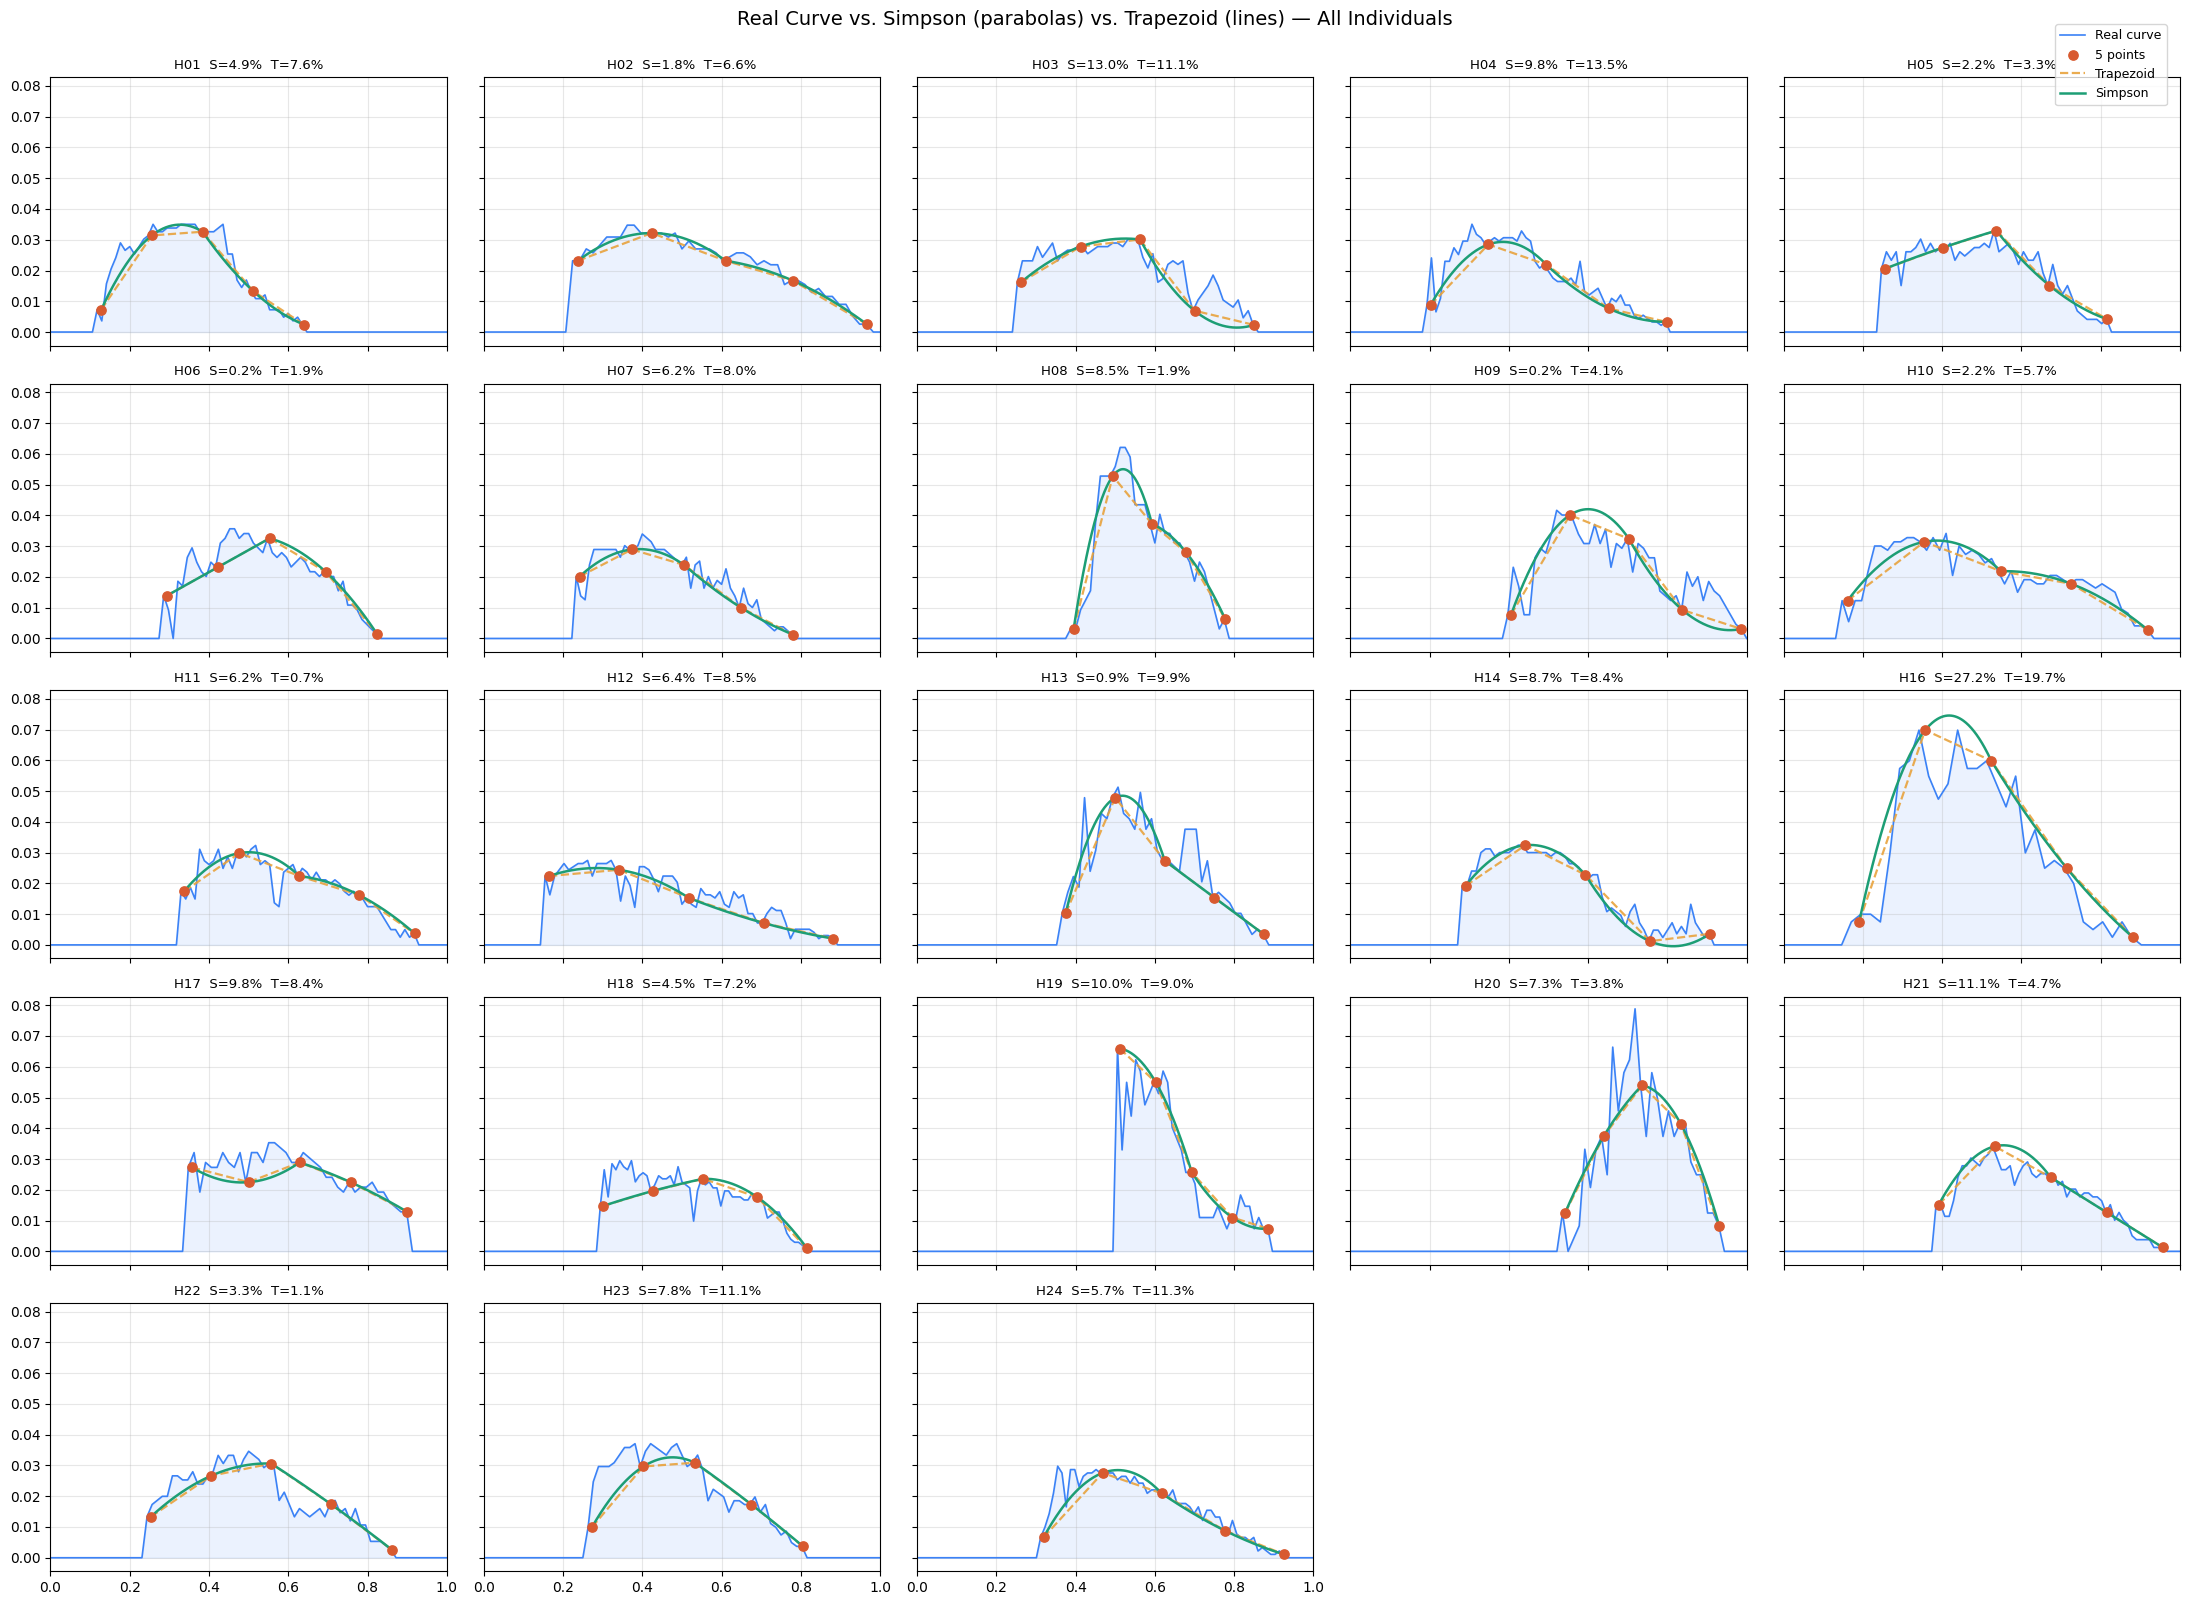

In [41]:
ids = sorted(df_sori_real["individual_id"].unique())

n_cols = 5
n_rows = int(np.ceil(len(ids) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 3.2 * n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for i, ind in enumerate(ids):
    group = df_sori_real[df_sori_real["individual_id"] == ind].sort_values("row_id", ascending=True).reset_index(drop=True)
    total = group["n_sori_per_row"].sum()
    proportion = group["n_sori_per_row"] / total
    x_real = np.linspace(0, 1, len(group))

    points_row = df_shape_points[df_shape_points["individual_id"] == ind].iloc[0]
    x5 = np.array([points_row["base_pos"], points_row["q1_pos"], points_row["center_pos"],
                   points_row["q3_pos"], points_row["apex_pos"]])
    y5_abs = np.array([points_row["sori_base"], points_row["sori_q1"], points_row["sori_center"],
                        points_row["sori_q3"], points_row["sori_apex"]])
    y5 = y5_abs / total

    error_simpson = points_row["error_pct_simpson"]
    error_trapezoid = points_row["error_pct_trapezoid"]

    coef1 = np.polyfit(x5[:3], y5[:3], 2)
    coef2 = np.polyfit(x5[2:], y5[2:], 2)
    xs1 = np.linspace(x5[0], x5[2], 200)
    xs2 = np.linspace(x5[2], x5[4], 200)
    ys1 = np.polyval(coef1, xs1)
    ys2 = np.polyval(coef2, xs2)

    axes[i].plot(x_real, proportion, color="#3b82f6", lw=1.2, label="Real curve")
    axes[i].fill_between(x_real, proportion, alpha=0.10, color="#3b82f6")

    axes[i].scatter(x5, y5, color="#D85A30", s=45, zorder=5, label="5 points")

    axes[i].plot(x5, y5, "--", color="#E8A33D", lw=1.6, alpha=0.9, label="Trapezoid")

    axes[i].plot(xs1, ys1, color="#1D9E75", lw=1.8, label="Simpson")
    axes[i].plot(xs2, ys2, color="#1D9E75", lw=1.8)

    axes[i].set_title(f"{ind}  S={error_simpson:.1f}%  T={error_trapezoid:.1f}%", fontsize=9.5)
    axes[i].grid(alpha=0.3)
    axes[i].set_xlim(0, 1)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.99, 0.995), fontsize=9)

fig.suptitle("Real Curve vs. Simpson (parabolas) vs. Trapezoid (lines) — All Individuals", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

## 8. Hybrid Approach

Since neither method fully dominates the other, Simpson offers better average precision, Trapezoid is more stable against sharp peaks like H16's, we test a third approach: averaging both estimates. The logic is that if Simpson's and Trapezoid's errors are not perfectly correlated, averaging them could cancel out some of each method's individual mistakes.

In [42]:
df_shape_points["sori_estimated_hybrid"] = (df_shape_points["sori_estimated_simpson"] + df_shape_points["sori_estimated_trapezoid"]) / 2
df_shape_points["error_pct_hybrid"] = (
    (df_shape_points["sori_estimated_hybrid"] - df_shape_points["total_real"]).abs() / df_shape_points["total_real"] * 100
).round(1)

print(f"Simpson   - mean: {df_shape_points['error_pct_simpson'].mean():.1f}%, median: {df_shape_points['error_pct_simpson'].median():.1f}%, max: {df_shape_points['error_pct_simpson'].max():.1f}%")
print(f"Trapezoid - mean: {df_shape_points['error_pct_trapezoid'].mean():.1f}%, median: {df_shape_points['error_pct_trapezoid'].median():.1f}%, max: {df_shape_points['error_pct_trapezoid'].max():.1f}%")
print(f"Hybrid    - mean: {df_shape_points['error_pct_hybrid'].mean():.1f}%, median: {df_shape_points['error_pct_hybrid'].median():.1f}%, max: {df_shape_points['error_pct_hybrid'].max():.1f}%")

Simpson   - mean: 6.9%, median: 6.2%, max: 27.2%
Trapezoid - mean: 7.3%, median: 7.6%, max: 19.7%
Hybrid    - mean: 6.9%, median: 6.2%, max: 23.4%


Averaging both estimates preserves Simpson's average and median performance (6.9% / 6.2%) while reducing its worst-case error from 27.2% to 23.4% on H16, confirming that the two methods' errors are not perfectly correlated, so combining them cancels out part of each one's individual mistakes. The hybrid does not match Trapezoid's worst-case stability (19.7%), but offers the best overall balance between average accuracy and resistance to the method's main failure mode (sharp, narrow peaks).

## 9. Sensitivity Check: 9-Point Resolution

`03_spatial_distribution_imputation` (Section 6.4.1) found that reconstruction fidelity keeps
improving from n=5 to n=10 after which it plateaus. That result, however, measures shape
reconstruction fidelity (Pearson r, MAE against the real proportion curve), not total-count
estimation error, the metric this notebook actually cares about. The two are related but not
interchangeable, so the improvement seen there does not automatically transfer here.

We test this directly, in this notebook's own metric, using n=9 rather than n=10: composite
Simpson's 1/3 rule requires an even number of subintervals (odd number of points), and n=5 (4
intervals) already satisfies that. n=9 (8 intervals) is the next resolution that keeps a pure
Simpson's rule without mixing in a 3/8 panel, which n=10 (9 intervals, odd) would require.

A convenient property of n=9: at evenly spaced fractions 0, 1/8, 2/8, ..., 8/8, the positions
1/4, 1/2, and 3/4 fall exactly on the 9-point grid, meaning the original 5 points (base, Q1,
center, Q3, apex) are a subset of the 9-point scheme. This isolates the effect of the 4 added
intermediate points rather than testing a completely different sampling design.

The trade-off is worth stating precisely: 9 points is 80% more than 5 in relative terms, but only
4 additional rows in absolute terms, still a small fraction of the 60-100 rows this notebook is
designed to avoid counting. So the real question is not whether 9 points is "a lot" in isolation,
but whether the resulting error reduction, if any, justifies those 4 extra rows.

### 9.1 Recomputing 9 Characteristic Points

We repeat the extraction of Section 3, but sampling 9 evenly spaced rows within the fertile zone
instead of 5. Points p1, p3, p5, p7, p9 correspond to base, Q1, center, Q3, and apex respectively;
p2, p4, p6, p8 are the new intermediate points.

In [43]:
def extract_nine_points(group):
    group = group.sort_values("row_id", ascending=True).reset_index(drop=True)
    with_sori = group[group["n_sori_per_row"] > 0]

    idx_start = with_sori.index.min()
    idx_end = with_sori.index.max()
    fertile_zone = group.loc[idx_start:idx_end].reset_index(drop=True)
    n_fertile_rows = len(fertile_zone)

    nine_indices = np.linspace(0, n_fertile_rows - 1, 9).round().astype(int)
    positions = fertile_zone.loc[nine_indices, "relative_position"].values
    values = fertile_zone.loc[nine_indices, "n_sori_per_row"].values

    labels = ["p1", "p2", "p3", "p4", "p5", "p6", "p7", "p8", "p9"]
    data = {
        "n_fertile_rows": n_fertile_rows,
        "n_rows_total": group["n_rows_total"].iloc[0],
        "total_real": group["n_sori_per_row"].sum(),
    }
    for lbl, pos, val in zip(labels, positions, values):
        data[f"{lbl}_pos"] = pos
        data[f"sori_{lbl}"] = val

    return pd.Series(data)


df_shape_points_9 = (
    df_sori_real.groupby("individual_id")
    .apply(extract_nine_points, include_groups=False)
    .reset_index()
)

df_shape_points_9.round(3)

,individual_id,n_fertile_rows,n_rows_total,total_real,p1_pos,sori_p1,p2_pos,sori_p2,p3_pos,sori_p3,...,p5_pos,sori_p5,p6_pos,sori_p6,p7_pos,sori_p7,p8_pos,sori_p8,p9_pos,sori_p9
0,H01,45.0,86.0,1656.0,0.128,12.0,0.198,44.0,0.256,52.0,...,0.384,54.0,0.453,42.0,0.512,22.0,0.570,12.0,0.640,4.0
1,H02,44.0,59.0,1554.0,0.237,36.0,0.322,48.0,0.424,50.0,...,0.610,36.0,0.695,34.0,0.780,26.0,0.881,18.0,0.966,4.0
2,H03,48.0,80.0,1728.0,0.262,28.0,0.338,46.0,0.412,48.0,...,0.562,52.0,0.625,30.0,0.700,12.0,0.775,18.0,0.850,4.0
3,H04,54.0,89.0,1826.0,0.202,16.0,0.281,46.0,0.348,52.0,...,0.494,40.0,0.573,28.0,0.652,14.0,0.719,10.0,0.798,6.0
4,H05,47.0,82.0,1456.0,0.256,30.0,0.329,38.0,0.402,40.0,...,0.537,48.0,0.610,38.0,0.671,22.0,0.744,10.0,0.817,6.0
5,H06,46.0,85.0,1290.0,0.294,18.0,0.365,38.0,0.424,30.0,...,0.553,42.0,0.624,32.0,0.694,28.0,0.753,14.0,0.824,2.0
6,H07,50.0,91.0,1590.0,0.242,32.0,0.308,46.0,0.374,46.0,...,0.505,38.0,0.582,26.0,0.648,16.0,0.714,8.0,0.780,2.0
7,H08,32.0,81.0,644.0,0.395,2.0,0.444,10.0,0.494,34.0,...,0.593,24.0,0.630,22.0,0.679,18.0,0.728,14.0,0.778,4.0
8,H09,44.0,74.0,1296.0,0.405,10.0,0.473,34.0,0.554,52.0,...,0.703,42.0,0.770,34.0,0.838,12.0,0.919,20.0,0.986,4.0
9,H10,48.0,62.0,1464.0,0.161,18.0,0.258,44.0,0.355,46.0,...,0.548,32.0,0.629,28.0,0.726,26.0,0.823,24.0,0.919,4.0


#### 9.1.1 Visual Check: 9 Points on the Real Curve

We overlay the 9 sampled points on each individual's real distribution curve, the same visual
check performed in Section 4 for the 5-point scheme, to see how much better the finer grid
tracks each curve, particularly around the sharp, off-center peaks that drove the largest errors
at n=5.

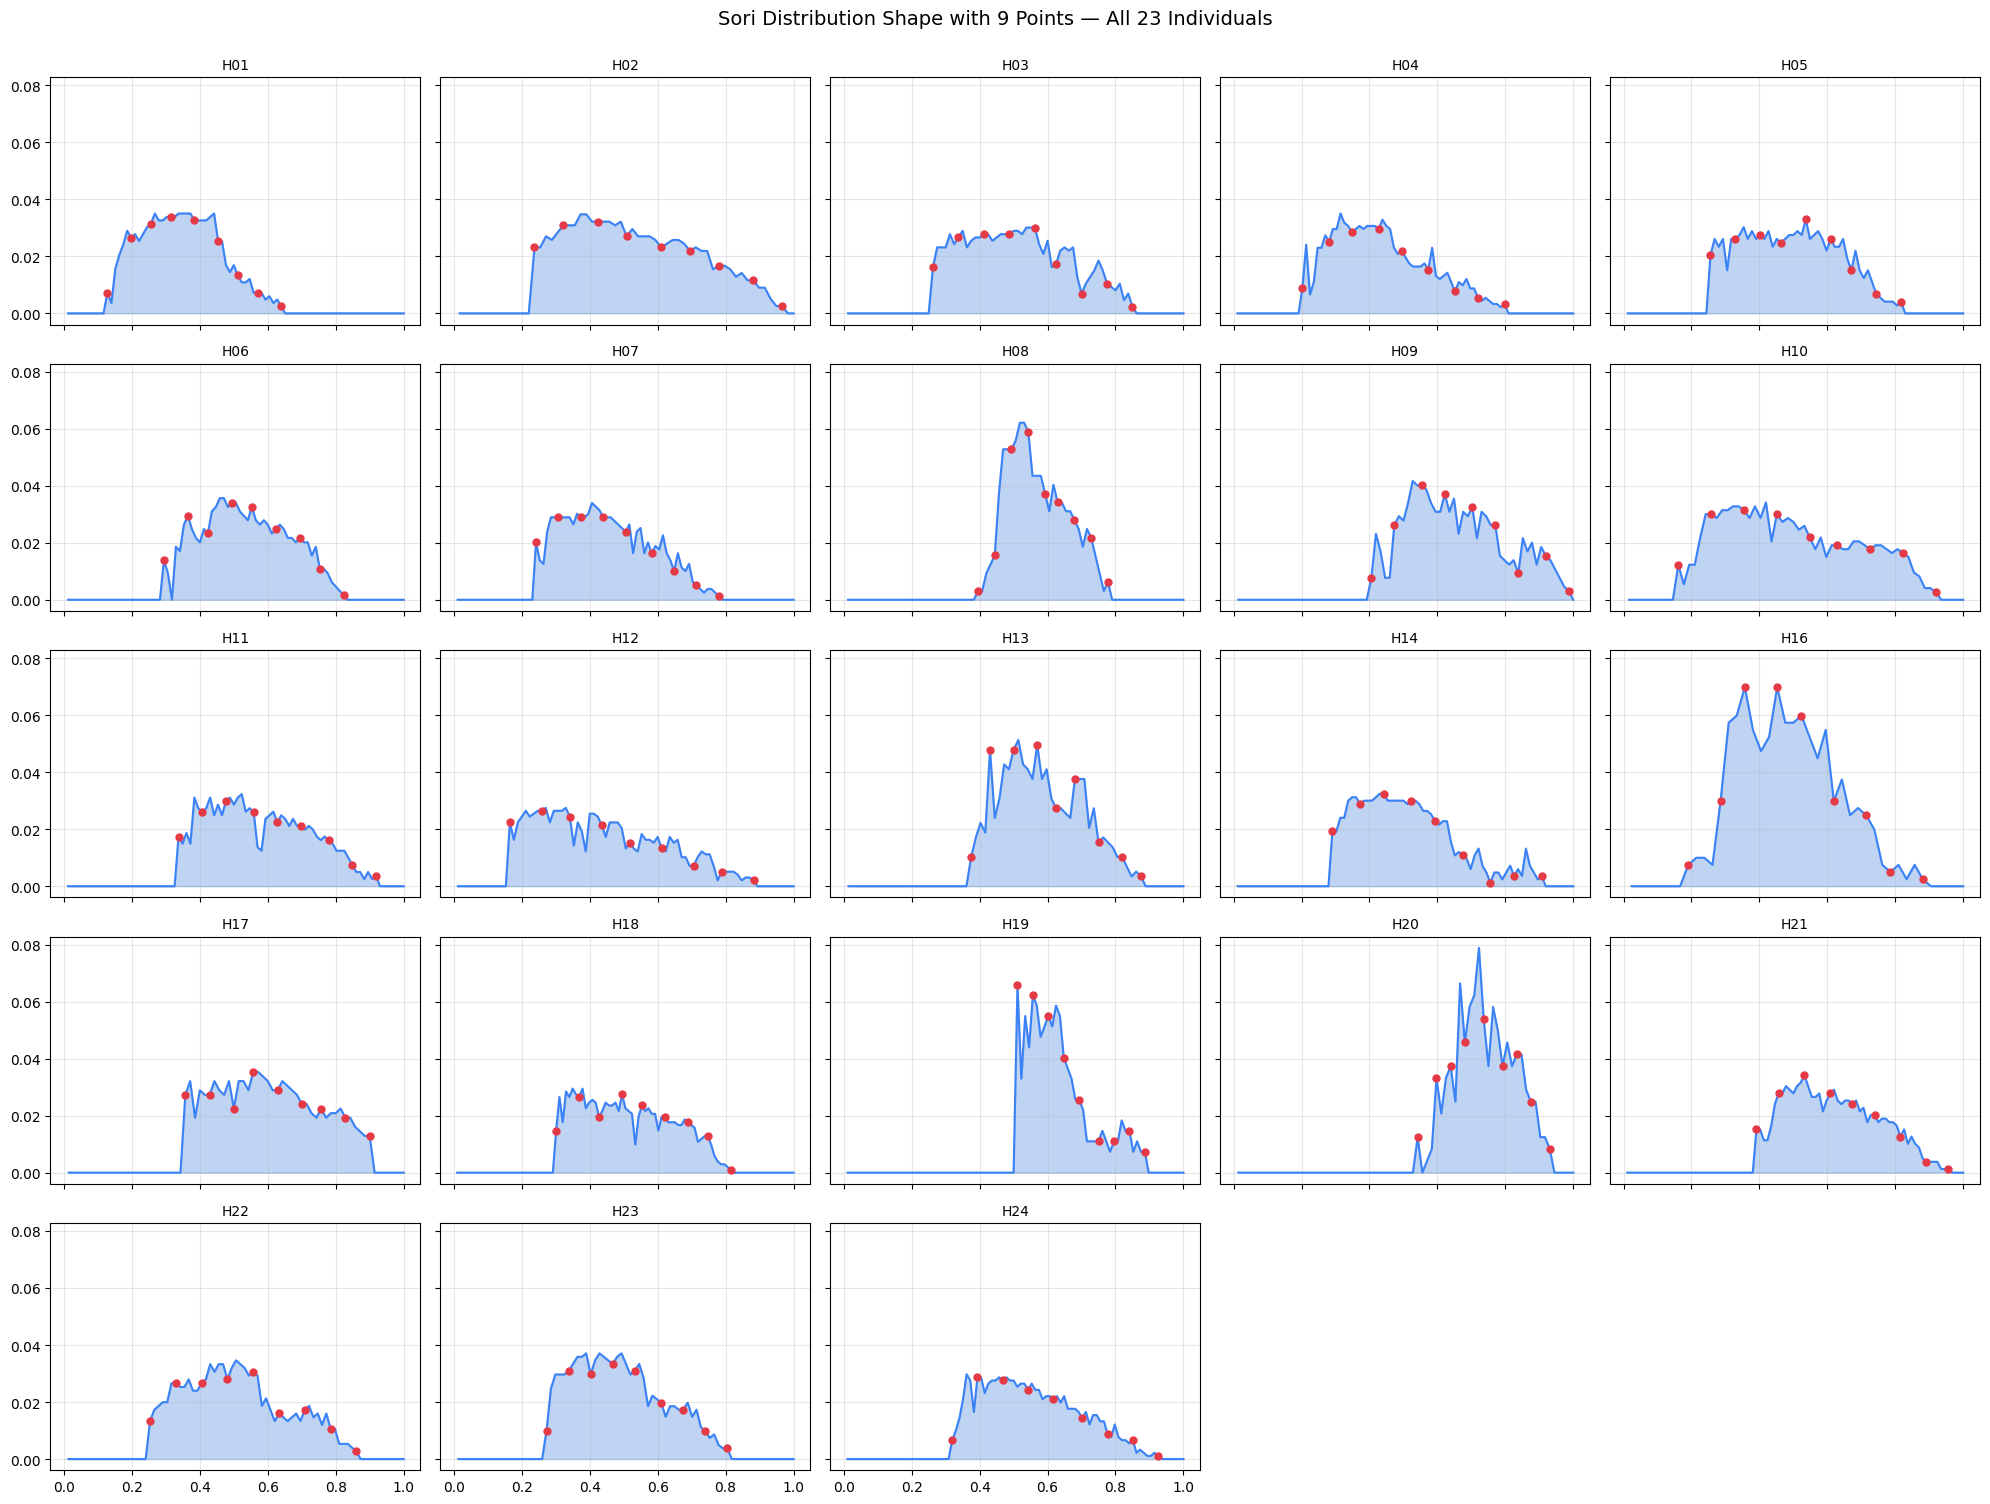

In [44]:
ids = sorted(df_sori_real["individual_id"].unique())
point_labels = ["p1", "p2", "p3", "p4", "p5", "p6", "p7", "p8", "p9"]

n_cols = 5
n_rows = int(np.ceil(len(ids) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3 * n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for i, ind in enumerate(ids):
    group = df_sori_real[df_sori_real["individual_id"] == ind].sort_values("row_id", ascending=True).reset_index(drop=True)
    total = group["n_sori_per_row"].sum()
    n_rows_total = group["row_id"].max()
    rel_pos = group["row_id"] / n_rows_total
    density = group["n_sori_per_row"] / total

    axes[i].plot(rel_pos, density, color="#3b82f6", lw=1.5)
    axes[i].fill_between(rel_pos, density, alpha=0.3, color="#2d73d4")

    points_row = df_shape_points_9[df_shape_points_9["individual_id"] == ind].iloc[0]
    points_x = [points_row[f"{lbl}_pos"] for lbl in point_labels]
    points_y = [points_row[f"sori_{lbl}"] / total for lbl in point_labels]

    axes[i].scatter(points_x, points_y, color="#e63946", s=25, zorder=3)
    axes[i].set_title(ind, fontsize=10)
    axes[i].grid(alpha=0.3)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

fig.suptitle("Sori Distribution Shape with 9 Points — All 23 Individuals", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

### 9.2 Simpson's Rule at n=9


With 8 intervals (9 points), composite Simpson's 1/3 rule uses weights 1-4-2-4-2-4-2-4-1:
`total ≈ N · (n_p1 + 4·n_p2 + 2·n_p3 + 4·n_p4 + 2·n_p5 + 4·n_p6 + 2·n_p7 + 4·n_p8 + n_p9) / 24`

In [45]:
df_shape_points_9["sori_estimated_simpson"] = (
    (df_shape_points_9["sori_p1"] + 4*df_shape_points_9["sori_p2"] + 2*df_shape_points_9["sori_p3"] +
     4*df_shape_points_9["sori_p4"] + 2*df_shape_points_9["sori_p5"] + 4*df_shape_points_9["sori_p6"] +
     2*df_shape_points_9["sori_p7"] + 4*df_shape_points_9["sori_p8"] + df_shape_points_9["sori_p9"]) / 24
) * df_shape_points_9["n_fertile_rows"]

df_shape_points_9["error_pct_simpson"] = (
    (df_shape_points_9["sori_estimated_simpson"] - df_shape_points_9["total_real"]).abs()
    / df_shape_points_9["total_real"] * 100
).round(1)

print(f"Mean error:   {df_shape_points_9['error_pct_simpson'].mean():.1f}%")
print(f"Median error: {df_shape_points_9['error_pct_simpson'].median():.1f}%")
print(f"Max error:    {df_shape_points_9['error_pct_simpson'].max():.1f}% "
      f"(individual: {df_shape_points_9.loc[df_shape_points_9['error_pct_simpson'].idxmax(), 'individual_id']})")

df_shape_points_9.sort_values("error_pct_simpson", ascending=False)[
    ["individual_id", "n_fertile_rows", "total_real", "sori_estimated_simpson", "error_pct_simpson"]
]

Mean error:   4.7%
Median error: 3.3%
Max error:    19.6% (individual: H13)


,individual_id,n_fertile_rows,total_real,sori_estimated_simpson,error_pct_simpson
12,H13,37.0,1170.0,1399.833333,19.6
17,H19,34.0,546.0,595.000000,9.0
8,H09,44.0,1296.0,1411.666667,8.9
5,H06,46.0,1290.0,1403.000000,8.8
16,H18,54.0,2036.0,2214.000000,8.7
9,H10,48.0,1464.0,1580.000000,7.9
14,H16,30.0,802.0,860.000000,7.2
19,H21,53.0,1582.0,1665.083333,5.3
2,H03,48.0,1728.0,1648.000000,4.6
21,H23,42.0,1618.0,1543.500000,4.6


### 9.3 Trapezoidal Rule at n=9

`total ≈ N · (n_p1/2 + n_p2 + n_p3 + n_p4 + n_p5 + n_p6 + n_p7 + n_p8 + n_p9/2) / 8`

In [46]:
df_shape_points_9["sori_estimated_trapezoid"] = (
    (df_shape_points_9["sori_p1"]/2 + df_shape_points_9["sori_p2"] + df_shape_points_9["sori_p3"] +
     df_shape_points_9["sori_p4"] + df_shape_points_9["sori_p5"] + df_shape_points_9["sori_p6"] +
     df_shape_points_9["sori_p7"] + df_shape_points_9["sori_p8"] + df_shape_points_9["sori_p9"]/2) / 8
) * df_shape_points_9["n_fertile_rows"]

df_shape_points_9["error_pct_trapezoid"] = (
    (df_shape_points_9["sori_estimated_trapezoid"] - df_shape_points_9["total_real"]).abs()
    / df_shape_points_9["total_real"] * 100
).round(1)

print(f"Mean error:   {df_shape_points_9['error_pct_trapezoid'].mean():.1f}%")
print(f"Median error: {df_shape_points_9['error_pct_trapezoid'].median():.1f}%")
print(f"Max error:    {df_shape_points_9['error_pct_trapezoid'].max():.1f}%")

Mean error:   4.6%
Median error: 4.5%
Max error:    12.3%


#### 9.3.1 Visual Check: Trapezoidal Reconstruction at n=9

We overlay the trapezoidal reconstruction (straight lines through the 9 points) on each individual's real curve, the same comparison done in Section 7 for the 5-point scheme, to see how much better the finer grid tracks sharp or irregular peaks like H16, H19, and H20

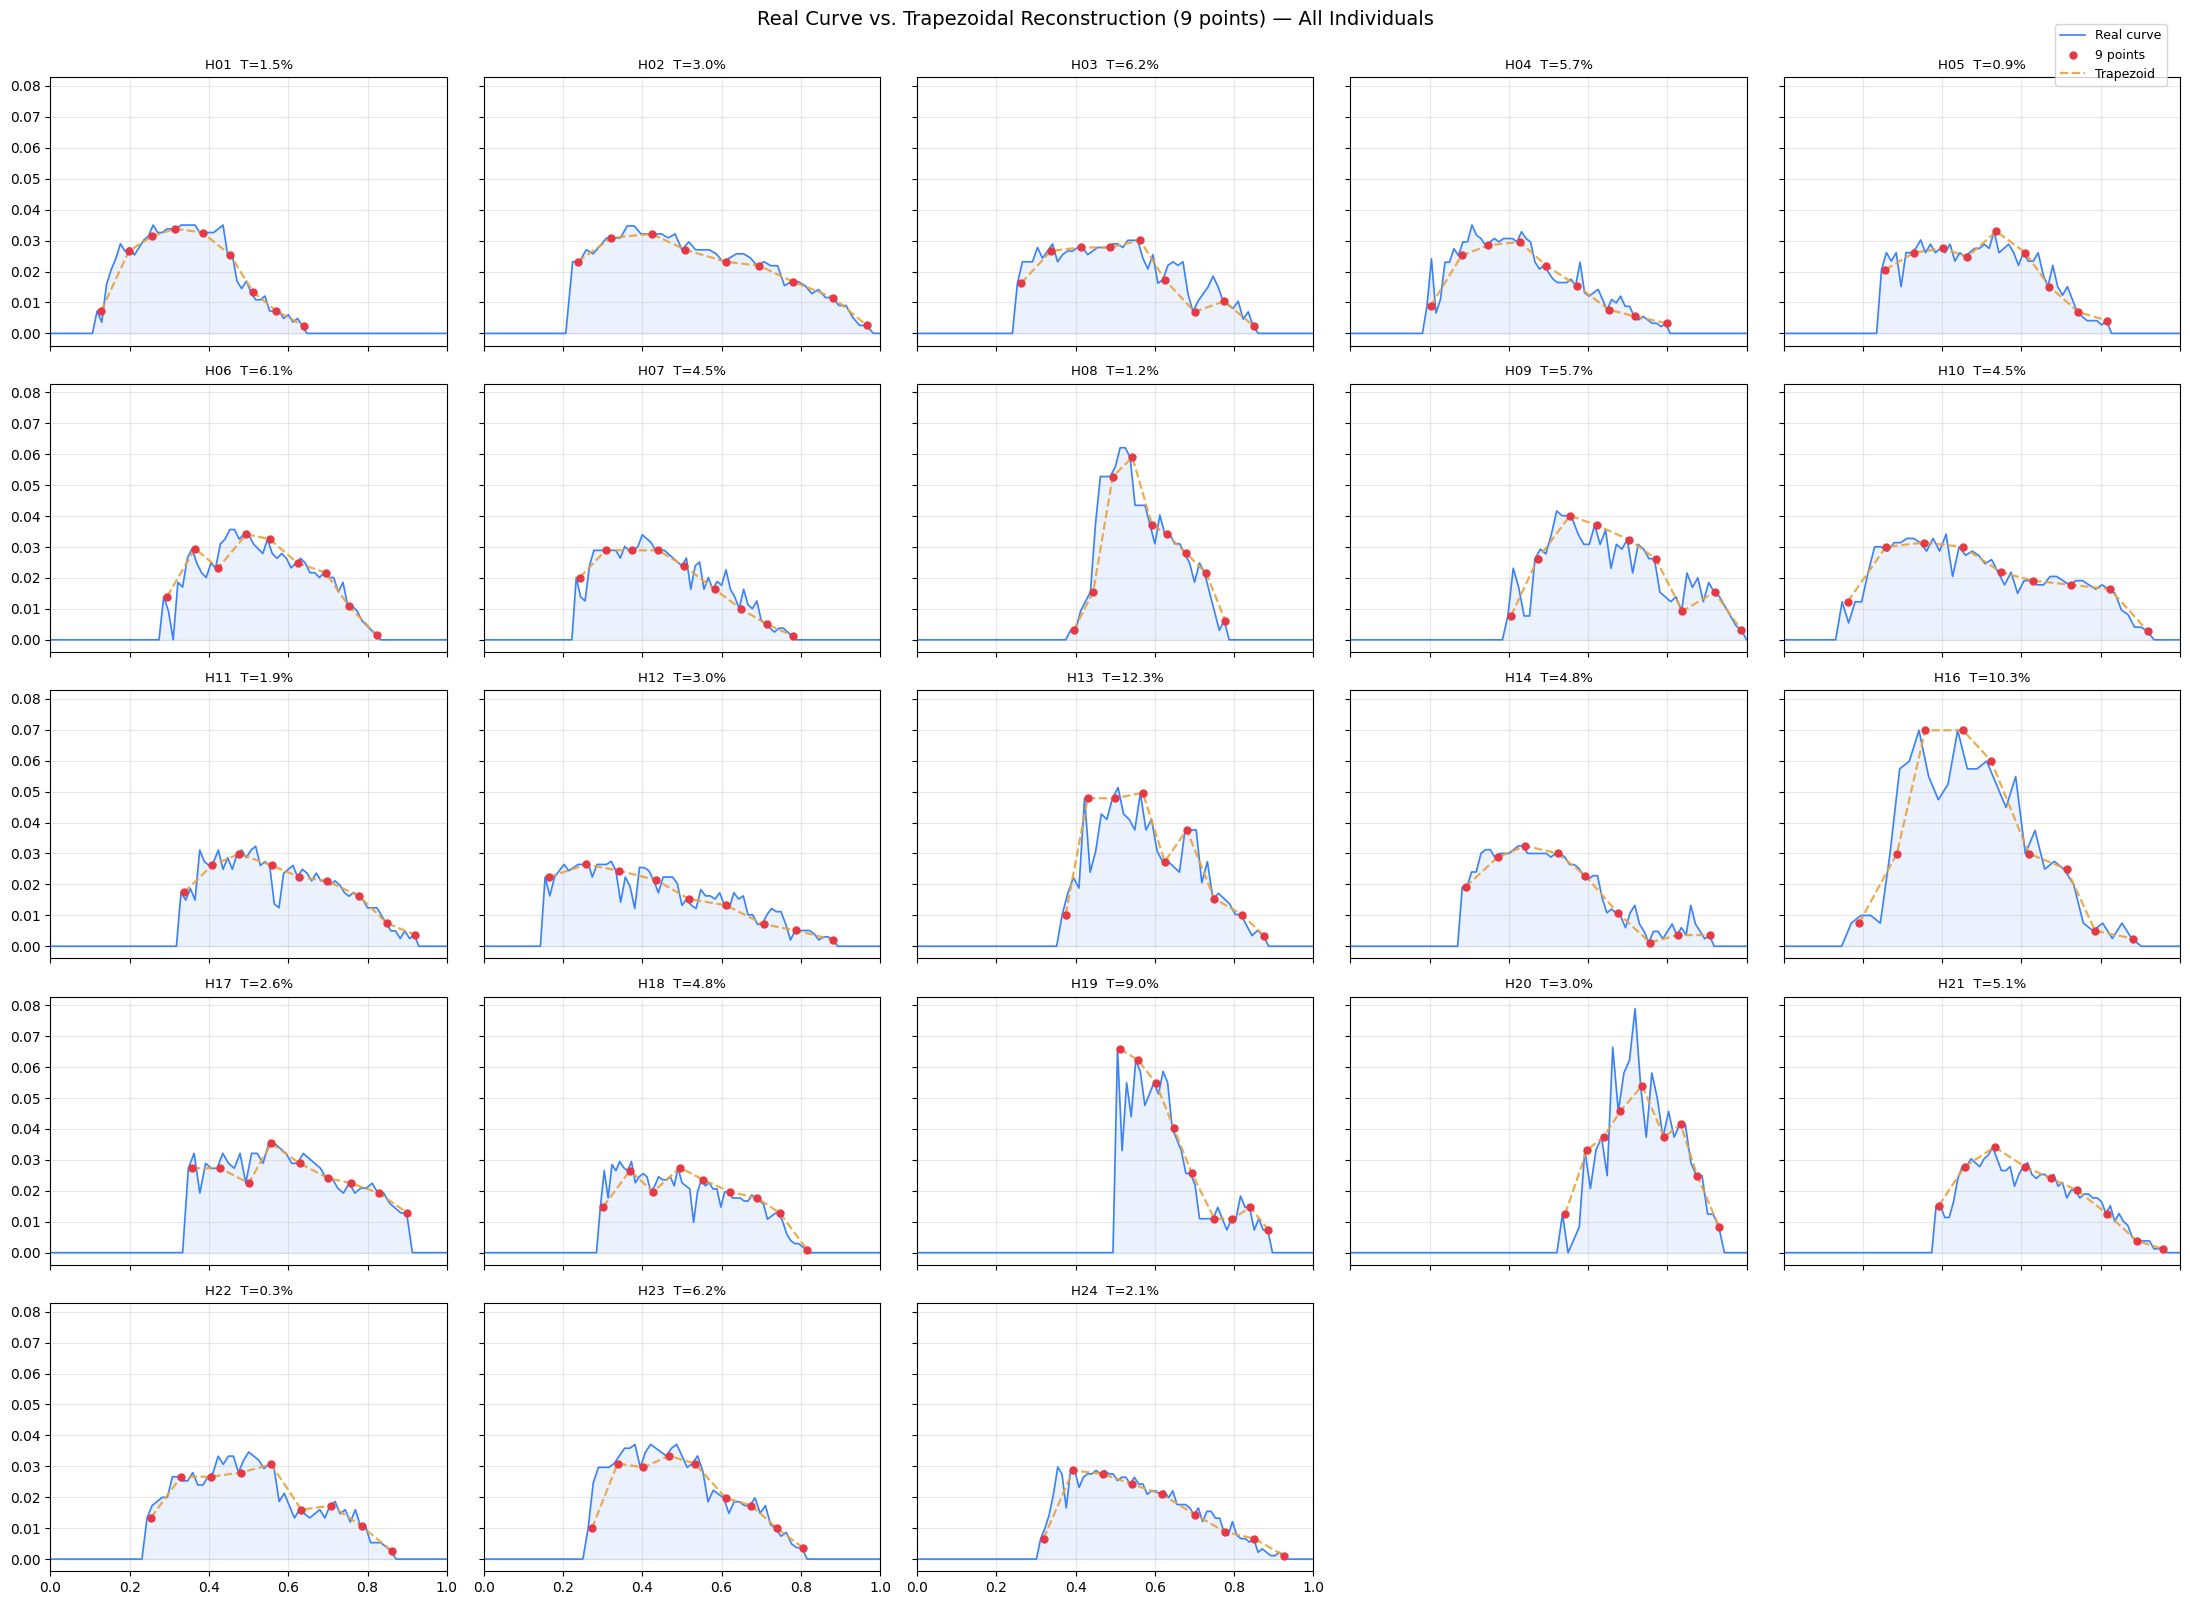

In [47]:
ids = sorted(df_sori_real["individual_id"].unique())
point_labels = ["p1", "p2", "p3", "p4", "p5", "p6", "p7", "p8", "p9"]

n_cols = 5
n_rows = int(np.ceil(len(ids) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 3.2 * n_rows), sharex=True, sharey=True)
axes = axes.flatten()

for i, ind in enumerate(ids):
    group = df_sori_real[df_sori_real["individual_id"] == ind].sort_values("row_id", ascending=True).reset_index(drop=True)
    total = group["n_sori_per_row"].sum()
    proportion = group["n_sori_per_row"] / total
    x_real = np.linspace(0, 1, len(group))

    points_row = df_shape_points_9[df_shape_points_9["individual_id"] == ind].iloc[0]
    x9 = np.array([points_row[f"{lbl}_pos"] for lbl in point_labels])
    y9_abs = np.array([points_row[f"sori_{lbl}"] for lbl in point_labels])
    y9 = y9_abs / total

    error_trapezoid = points_row["error_pct_trapezoid"]

    axes[i].plot(x_real, proportion, color="#3b82f6", lw=1.2, label="Real curve")
    axes[i].fill_between(x_real, proportion, alpha=0.10, color="#3b82f6")

    axes[i].scatter(x9, y9, color="#e63946", s=25, zorder=5, label="9 points")
    axes[i].plot(x9, y9, "--", color="#E8A33D", lw=1.6, alpha=0.9, label="Trapezoid")

    axes[i].set_title(f"{ind}  T={error_trapezoid:.1f}%", fontsize=9.5)
    axes[i].grid(alpha=0.3)
    axes[i].set_xlim(0, 1)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.99, 0.995), fontsize=9)

fig.suptitle("Real Curve vs. Trapezoidal Reconstruction (9 points) — All Individuals", fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig("../outputs/figures/06_trapezoid_n9.png", dpi=300, bbox_inches="tight")
plt.show()

### 9.4 Hybrid at n=9

In [48]:
df_shape_points_9["sori_estimated_hybrid"] = (
    df_shape_points_9["sori_estimated_simpson"] + df_shape_points_9["sori_estimated_trapezoid"]
) / 2
df_shape_points_9["error_pct_hybrid"] = (
    (df_shape_points_9["sori_estimated_hybrid"] - df_shape_points_9["total_real"]).abs()
    / df_shape_points_9["total_real"] * 100
).round(1)

print(f"Simpson   - mean: {df_shape_points_9['error_pct_simpson'].mean():.1f}%, "
      f"median: {df_shape_points_9['error_pct_simpson'].median():.1f}%, "
      f"max: {df_shape_points_9['error_pct_simpson'].max():.1f}%")
print(f"Trapezoid - mean: {df_shape_points_9['error_pct_trapezoid'].mean():.1f}%, "
      f"median: {df_shape_points_9['error_pct_trapezoid'].median():.1f}%, "
      f"max: {df_shape_points_9['error_pct_trapezoid'].max():.1f}%")
print(f"Hybrid    - mean: {df_shape_points_9['error_pct_hybrid'].mean():.1f}%, "
      f"median: {df_shape_points_9['error_pct_hybrid'].median():.1f}%, "
      f"max: {df_shape_points_9['error_pct_hybrid'].max():.1f}%")

Simpson   - mean: 4.7%, median: 3.3%, max: 19.6%
Trapezoid - mean: 4.6%, median: 4.5%, max: 12.3%
Hybrid    - mean: 4.5%, median: 4.2%, max: 16.0%


### 9.5 Comparison: 5 Points vs. 9 Points

We compare error metrics across both resolutions for all three methods, alongside the field-work
cost, 9 points means counting 80% more rows per individual, to judge whether the accuracy gain,
if any, justifies the added effort.

In [49]:
df_comparison_n = pd.DataFrame({
    "method": ["Simpson", "Trapezoid", "Hybrid"],
    "mean_error_n5":   [df_shape_points["error_pct_simpson"].mean(),   df_shape_points["error_pct_trapezoid"].mean(),   df_shape_points["error_pct_hybrid"].mean()],
    "mean_error_n9":   [df_shape_points_9["error_pct_simpson"].mean(), df_shape_points_9["error_pct_trapezoid"].mean(), df_shape_points_9["error_pct_hybrid"].mean()],
    "median_error_n5": [df_shape_points["error_pct_simpson"].median(),   df_shape_points["error_pct_trapezoid"].median(),   df_shape_points["error_pct_hybrid"].median()],
    "median_error_n9": [df_shape_points_9["error_pct_simpson"].median(), df_shape_points_9["error_pct_trapezoid"].median(), df_shape_points_9["error_pct_hybrid"].median()],
    "max_error_n5":    [df_shape_points["error_pct_simpson"].max(),   df_shape_points["error_pct_trapezoid"].max(),   df_shape_points["error_pct_hybrid"].max()],
    "max_error_n9":    [df_shape_points_9["error_pct_simpson"].max(), df_shape_points_9["error_pct_trapezoid"].max(), df_shape_points_9["error_pct_hybrid"].max()],
})
df_comparison_n.round(1)

,method,mean_error_n5,mean_error_n9,median_error_n5,median_error_n9,max_error_n5,max_error_n9
0,Simpson,6.9,4.7,6.2,3.3,27.2,19.6
1,Trapezoid,7.3,4.6,7.6,4.5,19.7,12.3
2,Hybrid,6.9,4.5,6.2,4.2,23.4,16.0


### 9.6 Statistical Comparison Among Methods at n=9

The mean error difference between Hybrid and Trapezoid at n=9 is small (4.5% vs. 4.6%), while
Trapezoid's advantage in worst-case error is larger (12.3% vs. 16.0%). Rather than relying on
the apparent size of the mean difference, we test it formally with a paired Wilcoxon signed-rank
test, consistent with the non-parametric approach used elsewhere in this notebook given the
skewed error distributions, to check whether Hybrid's small mean advantage is statistically
distinguishable from Trapezoid's, or whether Trapezoid's worst-case robustness should be the
deciding factor instead.

In [50]:


pairs = {
    "Hybrid vs Trapezoid": ("error_pct_hybrid", "error_pct_trapezoid"),
    "Hybrid vs Simpson":   ("error_pct_hybrid", "error_pct_simpson"),
    "Trapezoid vs Simpson": ("error_pct_trapezoid", "error_pct_simpson"),
}

for label, (col_a, col_b) in pairs.items():
    stat, p = wilcoxon(df_shape_points_9[col_a], df_shape_points_9[col_b])
    diff = (df_shape_points_9[col_a] - df_shape_points_9[col_b]).mean()
    print(f"{label}: mean diff = {diff:+.2f}pp, Wilcoxon p = {p:.3f}")

Hybrid vs Trapezoid: mean diff = -0.00pp, Wilcoxon p = 0.638
Hybrid vs Simpson: mean diff = -0.11pp, Wilcoxon p = 0.862
Trapezoid vs Simpson: mean diff = -0.11pp, Wilcoxon p = 0.626


In [51]:
df_shape_points_9["best_method_n9"] = np.select(
    [
        (df_shape_points_9["error_pct_hybrid"] <= df_shape_points_9["error_pct_trapezoid"]) &
        (df_shape_points_9["error_pct_hybrid"] <= df_shape_points_9["error_pct_simpson"]),
        (df_shape_points_9["error_pct_trapezoid"] <= df_shape_points_9["error_pct_hybrid"]) &
        (df_shape_points_9["error_pct_trapezoid"] <= df_shape_points_9["error_pct_simpson"]),
    ],
    ["Hybrid", "Trapezoid"],
    default="Simpson",
)
print(df_shape_points_9["best_method_n9"].value_counts())

best_method_n9
Simpson      12
Trapezoid     8
Hybrid        3
Name: count, dtype: int64


### 9.7 Conclusions

Moving from 5 to 9 points substantially reduces error across all three methods. Mean error falls from 6.9%/7.3%/6.9% (Simpson/Trapezoid/Hybrid) to 4.7%/4.6%/4.5%, while median error drops from 6.2% to 3.3% for Simpson and to 4.5%/4.2% for Trapezoid/Hybrid. Worst-case error also improves, from 27.2%→19.6% (Simpson), 19.7%→12.3% (Trapezoid), and 23.4%→16.0% (Hybrid).

These typical-case differences are not statistically significant: paired Wilcoxon tests find no difference between any pair of methods (Hybrid vs. Trapezoid p=0.638, Hybrid vs. Simpson p=0.862, Trapezoid vs. Simpson p=0.626). The small gaps in mean and median error are therefore consistent with sampling noise across 23 individuals. More informative is worst-case behavior: Simpson's narrow-peak failures produce the largest errors, whereas Trapezoid has the lowest worst-case error (12.3%). Several individuals show narrow, off-centre fertile peaks (H13, H16, H19, H20), which violate Simpson's local smoothness assumption. Trapezoid, by contrast, systematically underestimates concave curves rather than overshooting their peaks, making it the safer method for consistently accurate counts.

Because this notebook aims for a fast, low-effort field method rather than detailed curve reconstruction, Trapezoidal Rule at n=9 is the preferred final method. This choice is based not on a statistically significant average advantage, but on its more predictable error behavior and lower worst-case error. The Hybrid approach does not improve typical accuracy and partially reintroduces Simpson's overshoot error, with a worst case of 16.0%.

Nine points also remain practical in the field. They can be located by repeatedly halving the interval: the midpoint (p5), then the midpoints of each half (p3, p7), and finally the midpoints of the four quarters (p2, p4, p6, p8), together with the two endpoints. This requires no ruler or precise measurement and provides twice the resolution of the original 5-point scheme while remaining substantially faster than counting every row. Nine points should therefore be treated as a practical ceiling: sufficient resolution for reliable estimation without sacrificing the method's speed advantage. 



## 10. Final Results and Formula

In [52]:
df_sori_estimation_results = df_shape_points_9[["individual_id", "n_fertile_rows", "total_real", "sori_estimated_trapezoid", "error_pct_trapezoid"]] \
    .sort_values("error_pct_trapezoid", ascending=False).reset_index(drop=True)
df_sori_estimation_results["sori_estimated_trapezoid"] = df_sori_estimation_results["sori_estimated_trapezoid"].round().astype(int)
df_sori_estimation_results

,individual_id,n_fertile_rows,total_real,sori_estimated_trapezoid,error_pct_trapezoid
0,H13,37.0,1170.0,1314,12.3
1,H16,30.0,802.0,885,10.3
2,H19,34.0,546.0,595,9.0
3,H23,42.0,1618.0,1517,6.2
4,H03,48.0,1728.0,1620,6.2
5,H06,46.0,1290.0,1368,6.1
6,H04,54.0,1826.0,1721,5.7
7,H09,44.0,1296.0,1370,5.7
8,H21,53.0,1582.0,1663,5.1
9,H18,54.0,2036.0,2133,4.8


Based on the analysis above, including the resolution and method sensitivity checks in Section 9,
the total sori count of an individual can be estimated from 9 sampled rows along the fertile zone
using the Trapezoidal Rule:

**total ≈ N · (n_p1/2 + n_p2 + n_p3 + n_p4 + n_p5 + n_p6 + n_p7 + n_p8 + n_p9/2) / 8**

where N is the number of fertile rows, and n_p1 through n_p9 are the sori counts at 9 evenly
spaced rows across the fertile zone (p1=base, p3=Q1, p5=center, p7=Q3, p9=apex, with p2/p4/p6/p8
as intermediate points). This allows estimating total sori by counting only 9 strategic rows
instead of the typical 60-100, at a median error around 4.5%.

Trapezoid was chosen over Simpson and the Hybrid formula not because it minimizes mean error,
the Wilcoxon test (Section 9.6) found no statistically significant difference between methods,
but because its underlying assumption (no imposed curve smoothness) matches the sori
distribution shapes actually observed in this species, several individuals show narrow,
sharply peaked fertile zones that violate Simpson's implicit smoothness assumption and cause it
to overshoot the true peak (Section 5.3, Section 9.7). Trapezoid's bounded, systematically
conservative behavior on concave curves gives it the lowest worst-case error of the three methods
(12.3% vs. 16.0% for Hybrid and 19.6% for Simpson), making it the most defensible choice when
the goal is accuracy grounded in the biology of the distribution rather than robustness to
unknown future curve shapes.

## 11. Export

In [53]:
df_sori_estimation_results.to_csv("../data/processed/sori_estimation_validation.csv", index=False)
print(f"df_sori_estimation_results exported: {df_sori_estimation_results.shape[0]} rows × {df_sori_estimation_results.shape[1]} columns")

df_sori_estimation_results exported: 23 rows × 5 columns
